<a href="https://colab.research.google.com/github/herawati12/Projek_Semester5_Poptato/blob/hera/pcv_kentang_colab_(4).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PCV Kentang (Google Colab): Penentuan Kondisi Good vs Bad dengan Pengolahan Citra Digital

Proyek: *Implementasi Sistem Cerdas Berbasis IoT untuk Penentuan Grade Kentang Berdasarkan Berat dan Tingkat Kerusakan*

## Alur kerja
1. Akuisisi citra
2. Evaluasi kualitas citra
3. Image enhancement
4. Konversi ruang warna
5. Segmentasi objek
6. Ekstraksi kontur
7. Ekstraksi fitur warna
8. Ekstraksi fitur tekstur dan bentuk
9. Segmentasi fitur kerusakan
10. Hasil: **aturan ambang** pada tingkat kerusakan (tanpa training model), dengan classifier sebagai **pembanding opsional**

Label: `Buen estado` = **Good (0)**, `Defectuoso` = **Bad (1)**.

**Sebelum mulai:** unggah `dataset_papas_hibrido.zip` ke Google Drive, lalu sesuaikan `DRIVE_DATASET` di sel konfigurasi. Runtime **CPU** sudah cukup. Hasil disimpan di Drive.

## 0. Persiapan

In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
import os, random, zipfile, json, joblib
import numpy as np, pandas as pd
import cv2
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from scipy.stats import skew
from skimage.feature import graycomatrix, graycoprops, local_binary_pattern
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)
try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(x, **k): return x

# ===================== KONFIGURASI (ubah di sini) =====================
DRIVE_DATASET = "/content/drive/MyDrive/PBL_Kentang/dataset_papas_hibrido.zip"   # lokasi zip di Google Drive-mu
DATA_DIR   = "/content/dataset_papas_hibrido"          # salinan lokal Colab (jauh lebih cepat daripada Drive)
OUT_DIR    = "/content/drive/MyDrive/PBL_Kentang/hasil_pcv"   # hasil disimpan di Drive agar permanen

# Jumlah gambar PER KELAS yang diproses. 0 = pakai SEMUA (36.000 gambar, lama ~1 jam di 1 CPU)
MAX_TRAIN, MAX_VAL, MAX_TEST = 1000, 300, 500

N_JOBS      = -1       # -1 = semua core CPU; set 1 bila muncul error multiprocessing
USE_GRABCUT = True     # False = ekstraksi ~3x lebih cepat, segmentasi sedikit kurang halus
USE_CLAHE   = False    # CLAHE terbukti memperbesar noise pada dataset ini, jadi dimatikan
JALANKAN_PEMBANDING = True   # True = jalankan bagian opsional (classifier sebagai pembanding)

IMG_SIZE    = 224
KELAS       = {"Buen estado": 0, "Defectuoso": 1}   # 0 = Good, 1 = Bad
NAMA_LABEL  = ["Good", "Bad"]
SEED        = 42

# Parameter segmentasi kerusakan (skala kanal L OpenCV: 0-255)
KERNEL_RUSAK = 15      # ukuran kernel blackhat/tophat (bercak lebih kecil dari ini terdeteksi)
T_DARK       = 20      # ambang bercak GELAP (busuk, jamur hitam, luka)
T_BRIGHT     = 25      # ambang bercak TERANG (jamur putih, daging umbi terbuka)
T_ROUGH      = 12      # ambang area KASAR (variansi lokal tinggi)
MIN_BLOB     = 25      # bercak lebih kecil dari ini (piksel) dianggap noise / mata kentang
# ======================================================================

random.seed(SEED); np.random.seed(SEED)
os.makedirs(OUT_DIR, exist_ok=True)

In [3]:
import shutil

# Salin dataset dari Drive ke disk lokal Colab (sekali per sesi)
if not os.path.isdir(os.path.join(DATA_DIR, "train")):
    assert os.path.exists(DRIVE_DATASET), (
        f"File tidak ditemukan: {DRIVE_DATASET}\n"
        "Cek nama file dan lokasinya di Google Drive, lalu ubah DRIVE_DATASET di sel konfigurasi.")
    os.makedirs(DATA_DIR, exist_ok=True)
    if DRIVE_DATASET.lower().endswith(".zip"):
        print("Mengekstrak zip dari Drive ... (1-3 menit)")
        with zipfile.ZipFile(DRIVE_DATASET) as z:
            z.extractall(DATA_DIR)
    else:
        print("Menyalin folder dari Drive ... (lambat untuk 36 ribu file)")
        shutil.copytree(DRIVE_DATASET, DATA_DIR, dirs_exist_ok=True)
    if not os.path.isdir(os.path.join(DATA_DIR, "train")):      # folder pembungkus tambahan
        sub = [d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d))]
        if len(sub) == 1:
            DATA_DIR = os.path.join(DATA_DIR, sub[0])

for s in ("train", "val", "test"):
    print(s, {k: len(os.listdir(os.path.join(DATA_DIR, s, k))) for k in KELAS})

Mengekstrak zip dari Drive ... (1-3 menit)
train {'Buen estado': 11520, 'Defectuoso': 11520}
val {'Buen estado': 2880, 'Defectuoso': 2880}
test {'Buen estado': 3600, 'Defectuoso': 3600}


## Tahap 1. Akuisisi citra
Membaca citra dari file (dataset atau foto webcam) dan menyeragamkan ukurannya menjadi 224×224.

In [4]:
def akuisisi(sumber):
    """Baca citra (path atau array BGR) lalu samakan ukurannya."""
    img = cv2.imread(sumber) if isinstance(sumber, str) else sumber
    if img is None:
        raise ValueError(f"Gambar tidak bisa dibaca: {sumber}")
    return cv2.resize(img, (IMG_SIZE, IMG_SIZE))

## Tahap 2. Evaluasi kualitas citra
Mengukur **ketajaman**, **kecerahan**, **kontras**, dan **noise** pada citra mentah. Rentang normal diambil dari persentil 1–99 sampel dataset. Citra di luar rentang ditandai *perlu ambil ulang*, berguna untuk menolak foto webcam yang buram atau terlalu gelap.

In [5]:
def evaluasi_kualitas(img):
    """Ukur kualitas citra MENTAH sebelum diproses."""
    g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    return {"ketajaman": float(cv2.Laplacian(g, cv2.CV_64F).var()),                 # rendah = buram
            "kecerahan": float(g.mean()),                                            # terlalu gelap / terang
            "kontras":   float(g.std()),                                             # rendah = pudar
            "noise":     float(np.abs(g.astype(np.float32) - cv2.medianBlur(g, 3)).mean())}

def hitung_rentang_kualitas(daftar_path, persen=(1, 99)):
    """Rentang 'normal' = persentil 1-99 dari sampel dataset."""
    qs = pd.DataFrame([evaluasi_kualitas(akuisisi(p)) for p in daftar_path])
    return {k: (float(np.percentile(qs[k], persen[0])), float(np.percentile(qs[k], persen[1]))) for k in qs.columns}

def cek_kualitas(q, rentang):
    """Daftar masalah kualitas; list kosong = citra layak diproses."""
    masalah = []
    for k, (lo, hi) in rentang.items():
        if q[k] < lo:   masalah.append(f"{k} terlalu rendah ({q[k]:.1f} < {lo:.1f})")
        elif q[k] > hi: masalah.append(f"{k} terlalu tinggi ({q[k]:.1f} > {hi:.1f})")
    return masalah

In [6]:
sampel = []
for k in KELAS:
    d = os.path.join(DATA_DIR, "train", k)
    sampel += [os.path.join(d, f) for f in random.sample(os.listdir(d), min(150, len(os.listdir(d))))]
RENTANG = hitung_rentang_kualitas(sampel)
print("Rentang normal kualitas citra (persentil 1-99 dari dataset):")
for k, (lo, hi) in RENTANG.items():
    print(f"  {k:10s}: {lo:8.2f} .. {hi:8.2f}")

Rentang normal kualitas citra (persentil 1-99 dari dataset):
  ketajaman :    23.48 ..   381.55
  kecerahan :   139.00 ..   209.44
  kontras   :    23.01 ..    70.12
  noise     :     0.43 ..     1.93


## Tahap 3. Image enhancement
Mengurangi noise dengan Gaussian 5×5 lalu median 3×3. **CLAHE tidak dipakai secara default**: pada dataset ini CLAHE memperbesar noise dan tidak memperbaiki pemisahan Good/Bad (ubah `USE_CLAHE` bila ingin mencoba).

In [7]:
def enhancement(img, clahe=None):
    """Denoising: Gaussian 5x5 lalu median 3x3. CLAHE opsional (default mati)."""
    clahe = USE_CLAHE if clahe is None else clahe
    out = cv2.GaussianBlur(img, (5, 5), 0)
    out = cv2.medianBlur(out, 3)
    if clahe:
        lab = cv2.cvtColor(out, cv2.COLOR_BGR2LAB)
        lab[:, :, 0] = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(lab[:, :, 0])
        out = cv2.cvtColor(lab, cv2.COLOR_LAB2BGR)
    return out

## Tahap 4. Konversi ruang warna
BGR → abu-abu, **Lab** (dipakai untuk segmentasi dan kerusakan karena terang dan warna dipisah), dan **HSV** (untuk fitur warna).

In [8]:
def konversi_warna(img):
    """BGR -> gray, Lab, HSV (semua uint8 skala OpenCV)."""
    return (cv2.cvtColor(img, cv2.COLOR_BGR2GRAY),
            cv2.cvtColor(img, cv2.COLOR_BGR2LAB),
            cv2.cvtColor(img, cv2.COLOR_BGR2HSV))

## Tahap 5. Segmentasi objek
Warna latar diestimasi dari piksel tepi. Jarak warna **kromatik** (kanal a,b) ke latar di-threshold dengan Otsu, sehingga bayangan yang hanya berbeda terang tidak ikut terambil. Hasilnya dirapikan dengan morfologi dan GrabCut.

> Catatan: sebagian bayangan masih bisa lolos ke dalam mask, terutama di sisi kanan-bawah kentang.

In [9]:
def segmentasi(img, lab8):
    """
    Pisahkan kentang dari latar. Warna latar diestimasi dari piksel tepi; jarak KROMATIK (kanal a,b)
    ke latar di-threshold Otsu sehingga bayangan (hanya beda terang) tidak ikut terambil.
    """
    lab = lab8.astype(np.float32)
    b = 10
    border = np.concatenate([lab[:b].reshape(-1, 3), lab[-b:].reshape(-1, 3),
                             lab[:, :b].reshape(-1, 3), lab[:, -b:].reshape(-1, 3)])
    bg = np.median(border, axis=0)
    dist_ab = np.linalg.norm(lab[:, :, 1:] - bg[1:], axis=2)
    dist_L = np.abs(lab[:, :, 0] - bg[0]) * 0.25          # bobot kecil agar kentang gelap/busuk tetap terdeteksi
    dist = np.sqrt(dist_ab ** 2 + dist_L ** 2)
    dist8 = np.clip(dist * 255.0 / max(dist.max(), 1), 0, 255).astype(np.uint8)
    t, _ = cv2.threshold(dist8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    t = min(t, 0.45 * 255 * 0.5 + 20)                      # batasi agar kentang pucat tidak hilang
    mask = (dist8 > t).astype(np.uint8) * 255

    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, k)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, k)
    n, lbl, stats, _ = cv2.connectedComponentsWithStats(mask)
    if n > 1:
        big = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
        mask = np.where(lbl == big, 255, 0).astype(np.uint8)
    cnts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    filled = np.zeros_like(mask)
    if cnts:
        cv2.drawContours(filled, cnts, -1, 255, cv2.FILLED)
    mask = filled

    # penghalusan batas dengan GrabCut (menyingkirkan bayangan yang lolos threshold)
    if USE_GRABCUT and 0.05 < mask.mean() / 255.0 < 0.95:
        sure_fg = cv2.erode(mask, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (31, 31)))
        gc = np.full(mask.shape, cv2.GC_BGD, np.uint8)
        gc[mask > 0] = cv2.GC_PR_FGD
        gc[sure_fg > 0] = cv2.GC_FGD
        try:
            cv2.setRNGSeed(SEED)                           # hasil GrabCut jadi deterministik
            bgm, fgm = np.zeros((1, 65)), np.zeros((1, 65))
            cv2.grabCut(img, gc, None, bgm, fgm, 3, cv2.GC_INIT_WITH_MASK)
            gmask = np.where((gc == cv2.GC_FGD) | (gc == cv2.GC_PR_FGD), 255, 0).astype(np.uint8)
            gmask = cv2.morphologyEx(gmask, cv2.MORPH_OPEN, k)
            n, lbl, stats, _ = cv2.connectedComponentsWithStats(gmask)
            if n > 1:
                big = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
                gmask = np.where(lbl == big, 255, 0).astype(np.uint8)
            if 0.5 * mask.sum() < gmask.sum():             # tolak hasil yang menyusut ekstrem
                mask = gmask
        except cv2.error:
            pass

    ratio = mask.mean() / 255.0                            # fallback bila segmentasi gagal
    if ratio < 0.05 or ratio > 0.95:
        mask = np.zeros_like(mask)
        cv2.ellipse(mask, (IMG_SIZE // 2, IMG_SIZE // 2), (IMG_SIZE // 3, IMG_SIZE // 3), 0, 0, 360, 255, -1)
    return mask

## Tahap 6. Ekstraksi kontur
Kontur luar kentang, convex hull, luas, keliling, dan bounding box. Dipakai untuk fitur bentuk.

In [10]:
def ekstraksi_kontur(mask):
    """Kontur luar kentang + convex hull + bounding box."""
    cnts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    c = max(cnts, key=cv2.contourArea)
    return {"kontur": c, "hull": cv2.convexHull(c), "area": float(cv2.contourArea(c)),
            "perimeter": float(cv2.arcLength(c, True)), "bbox": cv2.boundingRect(c)}

## Tahap 7. Ekstraksi fitur warna
Rata-rata, simpangan baku, dan skewness pada kanal RGB, HSV, dan Lab, hanya di dalam mask kentang. Hue dinyatakan dengan sin/cos karena sifatnya melingkar.

In [11]:
def _stats(x):
    """mean, std, skewness"""
    if x.size < 3 or x.std() < 1e-6:
        return [float(x.mean()) if x.size else 0.0, 0.0, 0.0]
    return [float(x.mean()), float(x.std()), float(skew(x))]

def fitur_warna(img, hsv, lab, mask):
    m = mask > 0
    f = {}
    for nama, arr, chs in [("rgb", img[:, :, ::-1], "RGB"), ("hsv", hsv, "HSV"), ("lab", lab, "LAB")]:
        for i, c in enumerate(chs):
            if nama == "hsv" and c == "H":                 # hue melingkar -> sin/cos
                h = arr[:, :, 0][m].astype(np.float32) * 2 * np.pi / 180
                f["hsv_H_sin"], f["hsv_H_cos"] = float(np.sin(h).mean()), float(np.cos(h).mean())
                continue
            s = _stats(arr[:, :, i][m].astype(np.float32))
            f[f"{nama}_{c}_mean"], f[f"{nama}_{c}_std"], f[f"{nama}_{c}_skew"] = s
    return f

## Tahap 8. Ekstraksi fitur tekstur dan bentuk
- **Tekstur:** GLCM (contrast, dissimilarity, homogeneity, energy, correlation, ASM), histogram LBP, kepadatan tepi, variansi Laplacian.
- **Bentuk:** rasio luas, aspect ratio, circularity, solidity, eccentricity, *convexity defects* (tunas/potongan), dan Hu moments.

In [12]:
def fitur_tekstur(gray, mask):
    m = mask > 0
    x, y, w, h = cv2.boundingRect(mask)
    crop, cm = gray[y:y + h, x:x + w], m[y:y + h, x:x + w]
    q = (crop // 8).astype(np.uint8)                       # 32 level abu-abu
    q[~cm] = 0
    glcm = graycomatrix(q, distances=[1, 3], angles=[0, np.pi / 4, np.pi / 2, 3 * np.pi / 4],
                        levels=32, symmetric=True, normed=True)
    f = {f"glcm_{p}": float(graycoprops(glcm, p).mean())
         for p in ("contrast", "dissimilarity", "homogeneity", "energy", "correlation", "ASM")}
    lbp = local_binary_pattern(gray, 8, 1, method="uniform")
    er = cv2.erode(mask, np.ones((5, 5), np.uint8)) > 0
    hist, _ = np.histogram(lbp[er], bins=10, range=(0, 10), density=True)
    f.update({f"lbp_{i}": float(v) for i, v in enumerate(hist)})
    f["edge_density"] = float((cv2.Canny(gray, 50, 150)[er] > 0).mean())
    f["laplacian_var"] = float(cv2.Laplacian(gray, cv2.CV_64F)[er].var())
    return f

def fitur_bentuk(K):
    c, hull = K["kontur"], K["hull"]
    area, per = K["area"], K["perimeter"]
    harea, hper = max(cv2.contourArea(hull), 1), max(cv2.arcLength(hull, True), 1)
    x, y, w, h = K["bbox"]
    f = {"area_ratio": area / (IMG_SIZE ** 2),
         "aspect_ratio": max(w, h) / max(min(w, h), 1),
         "extent": area / max(w * h, 1),
         "circularity": 4 * np.pi * area / max(per ** 2, 1),
         "solidity": area / harea,
         "convexity": hper / max(per, 1)}
    if len(c) >= 5:
        (_, _), (MA, ma), _ = cv2.fitEllipse(c)
        a, b = max(MA, ma), max(min(MA, ma), 1e-6)
        f["eccentricity"] = float(np.sqrt(max(1 - (b / a) ** 2, 0)))
    else:
        f["eccentricity"] = 0.0
    depths = np.array([])                                  # cacat bentuk (tunas, potongan)
    try:
        d = cv2.convexityDefects(c, cv2.convexHull(c, returnPoints=False))
        if d is not None:
            depths = d.reshape(-1, 4)[:, 3] / 256.0
    except cv2.error:
        pass
    f["cvx_defect_n"] = float((depths > 3).sum())
    f["cvx_defect_max"] = float(depths.max()) if depths.size else 0.0
    f["cvx_defect_sum"] = float(depths.sum())
    for i, v in enumerate(cv2.HuMoments(cv2.moments(c)).flatten()):
        f[f"hu_{i+1}"] = float(-np.sign(v) * np.log10(abs(v) + 1e-30))
    return f

## Tahap 9. Segmentasi fitur kerusakan
Di dalam mask kentang, area rusak dipisahkan menjadi tiga jenis:

| Jenis | Metode | Mewakili |
|---|---|---|
| **Gelap** | blackhat pada kanal L | busuk, jamur hitam, luka |
| **Terang** | tophat pada kanal L | jamur putih, daging umbi terbuka |
| **Kasar** | variansi lokal kanal L | permukaan berlubang / bertekstur rusak |

Bercak lebih kecil dari `MIN_BLOB` piksel dibuang agar mata kentang normal tidak dihitung sebagai kerusakan.

In [13]:
def _elips(k):
    return cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))

def _bersihkan(mask_bool, min_blob=None):
    """Buang bercak < MIN_BLOB piksel (noise / mata kentang). Kembalikan mask bersih + daftar luas bercak."""
    min_blob = MIN_BLOB if min_blob is None else min_blob
    m = cv2.morphologyEx(mask_bool.astype(np.uint8) * 255, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    n, lbl, st, _ = cv2.connectedComponentsWithStats(m)
    ids = [i for i in range(1, n) if st[i, cv2.CC_STAT_AREA] >= min_blob]
    keep = np.isin(lbl, ids) if ids else np.zeros(m.shape, bool)
    return keep, np.array([st[i, cv2.CC_STAT_AREA] for i in ids], dtype=float)

def segmentasi_kerusakan(lab8, mask):
    """
    Pisahkan area rusak di dalam mask kentang:
      - GELAP  : blackhat pada kanal L  (busuk, jamur hitam, luka)
      - TERANG : tophat pada kanal L    (jamur putih, daging umbi terbuka)
      - KASAR  : variansi lokal L tinggi (permukaan berlubang / bertekstur rusak)
    """
    L = lab8[:, :, 0]
    area = max(int((mask > 0).sum()), 1)
    inner = cv2.erode(mask, np.ones((7, 7), np.uint8)) > 0          # hindari tepi kentang
    bh = cv2.morphologyEx(L, cv2.MORPH_BLACKHAT, _elips(KERNEL_RUSAK))
    th = cv2.morphologyEx(L, cv2.MORPH_TOPHAT, _elips(KERNEL_RUSAK))
    Lf = L.astype(np.float32)
    mu = cv2.blur(Lf, (7, 7))
    sd = np.sqrt(np.maximum(cv2.blur(Lf * Lf, (7, 7)) - mu * mu, 0))

    dark, a_d = _bersihkan((bh > T_DARK) & inner)
    bright, a_b = _bersihkan((th > T_BRIGHT) & inner)
    rough = (sd > T_ROUGH) & inner
    gab, a_g = _bersihkan(dark | bright | rough)

    mx = lambda a: (a.max() if len(a) else 0.0) / area
    f = {"dark_ratio": a_d.sum() / area, "dark_n": float(len(a_d)), "dark_max": mx(a_d),
         "bright_ratio": a_b.sum() / area, "bright_n": float(len(a_b)), "bright_max": mx(a_b),
         "rough_ratio": rough.sum() / area, "rough_ratio9": ((sd > 9) & inner).sum() / area,
         "rough_mean": float(sd[inner].mean()) if inner.any() else 0.0,
         "damage_ratio": gab.sum() / area, "damage_n": float(len(a_g)), "damage_max": mx(a_g)}
    return {"dark": dark, "bright": bright, "rough": rough, "gabungan": gab}, {k: float(v) for k, v in f.items()}

In [14]:
def proses_citra(sumber):
    """Seluruh alur PCV untuk satu citra. Mengembalikan hasil tiap tahap."""
    raw = akuisisi(sumber)                       # 1. akuisisi
    q = evaluasi_kualitas(raw)                   # 2. evaluasi kualitas
    img = enhancement(raw)                       # 3. enhancement
    gray, lab, hsv = konversi_warna(img)         # 4. konversi ruang warna
    mask = segmentasi(img, lab)                  # 5. segmentasi objek
    K = ekstraksi_kontur(mask)                   # 6. ekstraksi kontur
    f = {}
    f.update(fitur_warna(img, hsv, lab, mask))   # 7. fitur warna
    M, fk = segmentasi_kerusakan(lab, mask)      # 9. segmentasi fitur kerusakan
    f.update(fk)
    f.update(fitur_tekstur(gray, mask))          # 8. fitur tekstur dan bentuk
    f.update(fitur_bentuk(K))
    f = {k: (0.0 if not np.isfinite(v) else float(v)) for k, v in f.items()}
    return {"raw": raw, "q": q, "img": img, "gray": gray, "lab": lab, "hsv": hsv,
            "mask": mask, "kontur": K, "masks": M, "fitur": f}

def tampilkan_alur(P, hasil=None, aktif=None, masalah=None, ambang=None, judul=""):
    """Visualisasi tiap tahap untuk satu citra (untuk laporan)."""
    fig, ax = plt.subplots(2, 4, figsize=(16, 8.4))
    ax = ax.ravel()
    ax[0].imshow(P["raw"][:, :, ::-1]);                 ax[0].set_title("1. Citra asli")
    ax[1].imshow(P["img"][:, :, ::-1]);                 ax[1].set_title("3. Setelah enhancement")
    ax[2].imshow(P["lab"][:, :, 0], cmap="gray");       ax[2].set_title("4. Kanal L (Lab)")
    ax[3].imshow(P["hsv"][:, :, 1], cmap="gray");       ax[3].set_title("4. Kanal S (HSV)")
    seg = P["img"].copy(); seg[P["mask"] == 0] = (seg[P["mask"] == 0] * 0.15).astype(np.uint8)
    ax[4].imshow(seg[:, :, ::-1]);                      ax[4].set_title("5. Segmentasi objek")
    kn = P["img"].copy(); K = P["kontur"]
    cv2.drawContours(kn, [K["kontur"]], -1, (0, 255, 0), 2)
    cv2.drawContours(kn, [K["hull"]], -1, (255, 0, 0), 1)
    x, y, w, h = K["bbox"]; cv2.rectangle(kn, (x, y), (x + w, y + h), (0, 0, 255), 1)
    ax[5].imshow(kn[:, :, ::-1]);                       ax[5].set_title("6. Kontur (hijau), hull (biru), bbox (merah)", fontsize=9)
    ov = P["img"].copy(); M = P["masks"]
    for nm, warna in (("rough", (0, 255, 255)), ("bright", (255, 255, 0)), ("dark", (0, 0, 255))):
        ov[M[nm]] = (0.45 * ov[M[nm]] + 0.55 * np.array(warna)).astype(np.uint8)
    ax[6].imshow(ov[:, :, ::-1]);                       ax[6].set_title("9. Area rusak: gelap=merah, terang=cyan, kasar=kuning", fontsize=9)
    f = P["fitur"]
    teks = [f"{judul}", ""]
    for k in INDIKATOR:
        s = f"{k:13s}= {f[k]:.4f}"
        if ambang: s += f"  (ambang {ambang[k]:.4f})" + ("  <- MELEWATI" if k in (aktif or []) else "")
        teks.append(s)
    teks.append(f"{'damage_ratio':13s}= {f['damage_ratio']:.4f}")
    if hasil: teks += ["", f"HASIL: {hasil}"]
    if masalah is not None:
        teks += ["", "Kualitas citra: " + ("layak" if not masalah else "PERLU AMBIL ULANG")] + ["  - " + m for m in masalah]
    ax[7].axis("off"); ax[7].set_title("10. Hasil")
    ax[7].text(0.0, 1.0, "\n".join(teks), va="top", family="monospace", fontsize=9)
    for a in ax[:7]: a.axis("off")
    plt.tight_layout(); plt.show()

# indikator yang dipakai aturan keputusan (hasil eksplorasi: paling membedakan Good vs Bad)
INDIKATOR = ["rough_ratio", "dark_ratio", "bright_ratio"]

### Demo seluruh tahap pada satu citra
Panel 1–9 menampilkan hasil tiap tahap. Hasil keputusan baru muncul setelah aturan ambang dibuat di Tahap 10.

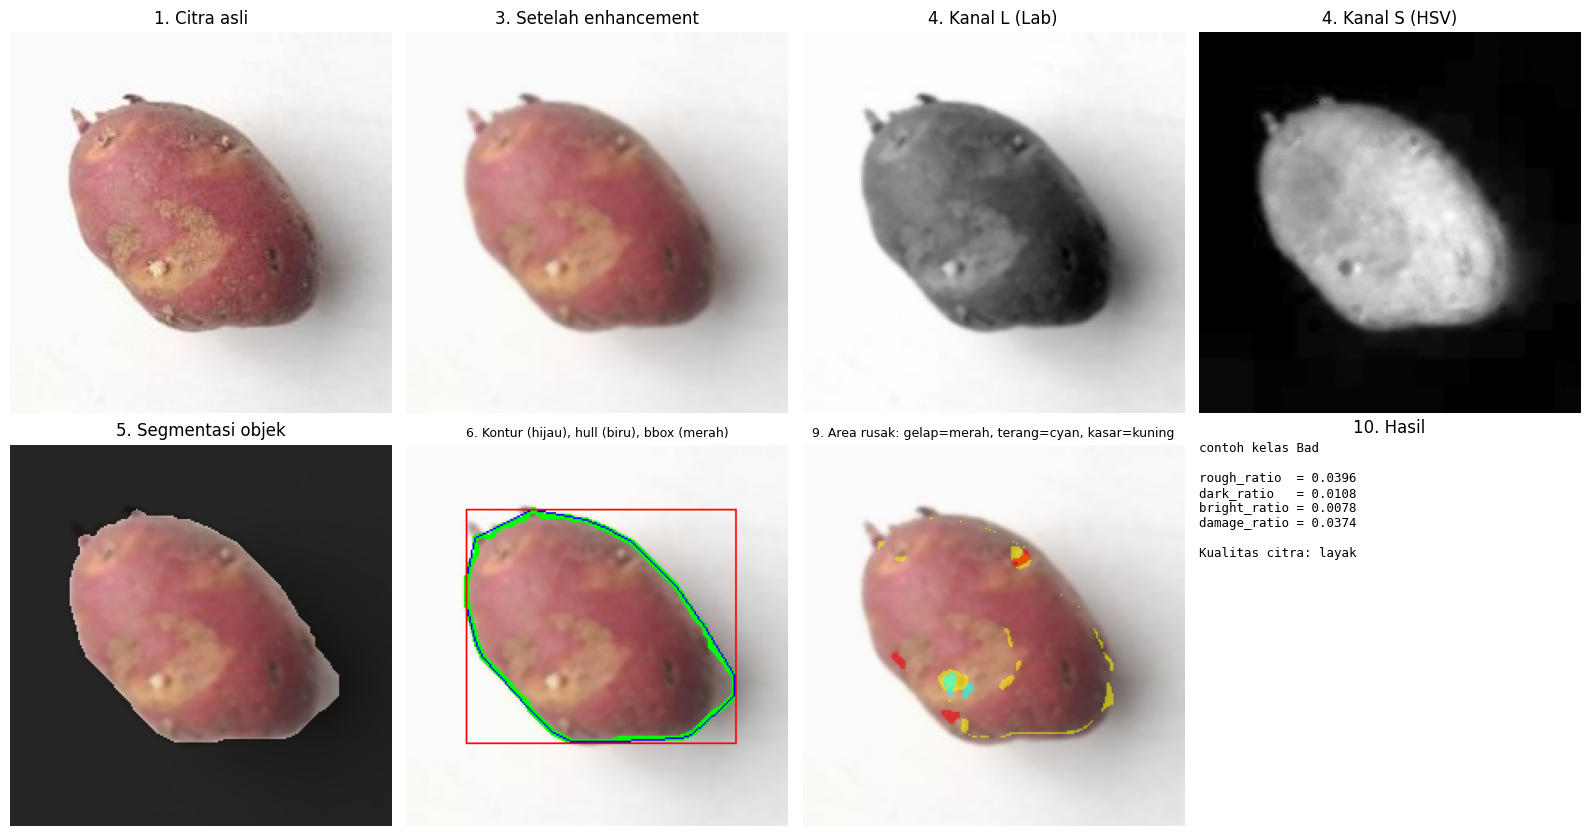

In [15]:
d = os.path.join(DATA_DIR, "train", "Defectuoso")
P_demo = proses_citra(os.path.join(d, random.choice(os.listdir(d))))
tampilkan_alur(P_demo, masalah=cek_kualitas(P_demo["q"], RENTANG), judul="contoh kelas Bad")

## Tahap 10. Hasil: aturan ambang pada tingkat kerusakan

**10a. Ekstraksi fitur seluruh dataset.** Disimpan ke CSV (`fitur/train.csv`, `val.csv`, `test.csv`). Bila CSV sudah ada, sel ini memakainya kembali.

In [16]:
FITUR_DIR = os.path.join(OUT_DIR, "fitur")
os.makedirs(FITUR_DIR, exist_ok=True)

def _proses(path, label):
    P = proses_citra(path)
    return P["fitur"], label

NAMA_FITUR = list(proses_citra(np.full((IMG_SIZE, IMG_SIZE, 3), 200, np.uint8))["fitur"].keys())
print("Jumlah fitur per gambar:", len(NAMA_FITUR))

def ekstrak_split(split, maks):
    csv = os.path.join(FITUR_DIR, f"{split}.csv")
    if os.path.exists(csv):
        print(f"{split}: pakai {csv} yang sudah ada")
        return pd.read_csv(csv)
    daftar = []
    for k, lab in KELAS.items():
        fs = sorted(os.listdir(os.path.join(DATA_DIR, split, k)))
        if maks and len(fs) > maks:
            fs = random.sample(fs, maks)
        daftar += [(os.path.join(DATA_DIR, split, k, f), lab) for f in fs]
    hasil = Parallel(n_jobs=N_JOBS)(delayed(_proses)(p, l) for p, l in tqdm(daftar, desc=split))
    df = pd.DataFrame([h[0] for h in hasil], columns=NAMA_FITUR)
    df["label"] = [h[1] for h in hasil]
    df["path"] = [p for p, _ in daftar]
    df.to_csv(csv, index=False)
    print(split, df.shape)
    return df

df_tr = ekstrak_split("train", MAX_TRAIN)
df_va = ekstrak_split("val",   MAX_VAL)
df_te = ekstrak_split("test",  MAX_TEST)

Jumlah fitur per gambar: 73
train: pakai /content/drive/MyDrive/PBL_Kentang/hasil_pcv/fitur/train.csv yang sudah ada
val: pakai /content/drive/MyDrive/PBL_Kentang/hasil_pcv/fitur/val.csv yang sudah ada
test: pakai /content/drive/MyDrive/PBL_Kentang/hasil_pcv/fitur/test.csv yang sudah ada


In [17]:
# Rata-rata indikator kerusakan per kelas
kol = INDIKATOR + ["damage_ratio", "dark_n", "bright_n"]
print(df_tr.groupby("label")[kol].mean().rename(index={0: "Good", 1: "Bad"}).round(4).T.to_string())

label           Good     Bad
rough_ratio   0.0500  0.1242
dark_ratio    0.0219  0.0581
bright_ratio  0.0080  0.0239
damage_ratio  0.0606  0.1507
dark_n        4.4500  8.4960
bright_n      1.8540  4.3380


**10b. Membuat aturan ambang.**
1. Ambang tiap indikator dicari dari data **train** (yang memaksimalkan akurasi).
2. Aturan: citra dinyatakan **Bad** bila minimal *N* dari 3 indikator (`rough_ratio`, `dark_ratio`, `bright_ratio`) melewati ambangnya.
3. Nilai *N* dipilih dari data **validasi**, lalu aturan dievaluasi **sekali** pada data **test**.

Tidak ada model yang dilatih. Hasilnya berupa angka ambang yang bisa dijelaskan dan dipindahkan ke Raspberry Pi atau ESP32.

In [18]:
# --- Mencari ambang tiap indikator dari data TRAIN (maksimumkan akurasi) ---
def cari_ambang(df, kolom):
    kandidat = np.unique(np.quantile(df[kolom], np.linspace(0.02, 0.98, 193)))
    akurasi = [((df[kolom] > t) == df.label).mean() for t in kandidat]
    i = int(np.argmax(akurasi))
    return float(kandidat[i]), float(akurasi[i])

AMBANG = {}
print("Ambang per indikator (dari train):")
for k in INDIKATOR:
    AMBANG[k], acc = cari_ambang(df_tr, k)
    print(f"  {k:13s} ambang = {AMBANG[k]:.4f} | akurasi sendiri di train = {acc:.3f}")

def jumlah_suara(df):
    return sum((df[k] > AMBANG[k]).astype(int) for k in INDIKATOR)

# --- Memilih jumlah indikator minimal (voting) berdasarkan VALIDASI ---
print("\nVoting: Bad bila minimal N dari 3 indikator melewati ambang")
terbaik_n, f1_terbaik = None, -1
for n in (1, 2, 3):
    f1v = f1_score(df_va.label, (jumlah_suara(df_va) >= n).astype(int))
    print(f"  N={n} | F1 validasi = {f1v:.3f}")
    if f1v > f1_terbaik:
        terbaik_n, f1_terbaik = n, f1v
MIN_VOTE = terbaik_n
print(f"-> dipakai N = {MIN_VOTE}")

json.dump({"ambang": AMBANG, "min_vote": MIN_VOTE, "indikator": INDIKATOR},
          open(os.path.join(OUT_DIR, "aturan_ambang.json"), "w"), indent=2)

def keputusan_aturan(fitur, ambang=None, min_vote=None):
    """Keputusan Good/Bad dari satu citra + indikator mana yang melewati ambang."""
    ambang = AMBANG if ambang is None else ambang
    min_vote = MIN_VOTE if min_vote is None else min_vote
    aktif = [k for k in INDIKATOR if fitur[k] > ambang[k]]
    return ("BAD" if len(aktif) >= min_vote else "GOOD"), aktif

Ambang per indikator (dari train):
  rough_ratio   ambang = 0.0501 | akurasi sendiri di train = 0.777
  dark_ratio    ambang = 0.0260 | akurasi sendiri di train = 0.742
  bright_ratio  ambang = 0.0061 | akurasi sendiri di train = 0.739

Voting: Bad bila minimal N dari 3 indikator melewati ambang
  N=1 | F1 validasi = 0.781
  N=2 | F1 validasi = 0.797
  N=3 | F1 validasi = 0.726
-> dipakai N = 2


Aturan ambang (tanpa training model):
{'Acc test': 0.795, 'Precision': 0.7547, 'Recall': 0.874, 'F1 test': 0.81}
              precision    recall  f1-score   support

        Good     0.8504    0.7160    0.7774       500
         Bad     0.7547    0.8740    0.8100       500

    accuracy                         0.7950      1000
   macro avg     0.8026    0.7950    0.7937      1000
weighted avg     0.8026    0.7950    0.7937      1000



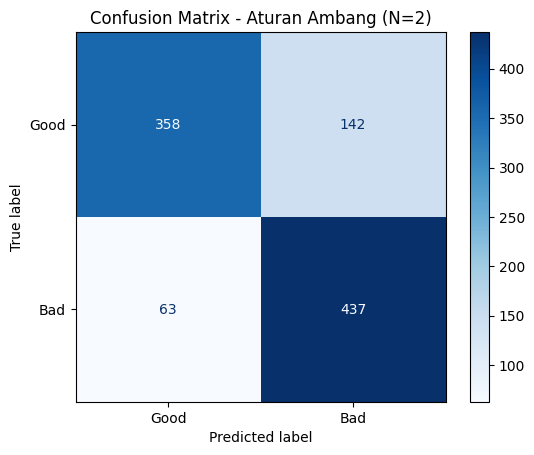

In [19]:
# --- Evaluasi aturan ambang pada TEST ---
yte = df_te.label.values
pred = (jumlah_suara(df_te) >= MIN_VOTE).astype(int).values
HASIL_ATURAN = {"Acc test": accuracy_score(yte, pred), "Precision": precision_score(yte, pred),
                "Recall": recall_score(yte, pred), "F1 test": f1_score(yte, pred)}
print("Aturan ambang (tanpa training model):")
print({k: round(v, 4) for k, v in HASIL_ATURAN.items()})
print(classification_report(yte, pred, target_names=NAMA_LABEL, digits=4))
ConfusionMatrixDisplay(confusion_matrix(yte, pred), display_labels=NAMA_LABEL).plot(cmap="Blues")
plt.title(f"Confusion Matrix - Aturan Ambang (N={MIN_VOTE})")
plt.savefig(os.path.join(OUT_DIR, "confusion_matrix_aturan.png"), dpi=150, bbox_inches="tight")
plt.show()

**10c. Prediksi citra.** Tampilan ringkas: citra masukan, segmentasi, dan keputusan Good/Bad beserta nilai tiap indikator. Tambahkan `detail=True` pada `prediksi_dan_tampilkan(...)` untuk menampilkan seluruh tahap alur (cocok untuk laporan).

In [20]:
def prediksi_dan_tampilkan(sumber, judul="", detail=False):
    """
    Prediksi Good/Bad satu citra dengan aturan ambang.
    Default: tampilan ringkas (citra masukan + segmentasi). detail=True: tampilkan seluruh tahap alur.
    """
    P = proses_citra(sumber)
    masalah = cek_kualitas(P["q"], RENTANG)
    hasil, aktif = keputusan_aturan(P["fitur"])
    nama = judul or os.path.basename(str(sumber))
    f = P["fitur"]

    print(f"{nama}: {len(aktif)} dari {len(INDIKATOR)} indikator melewati ambang (Bad bila >= {MIN_VOTE})  ->  {hasil}")
    for k in INDIKATOR:
        print(f"   {k:13s} {f[k]:.4f}  (ambang {AMBANG[k]:.4f})" + ("  <- melewati" if k in aktif else ""))
    if masalah:
        print("   Kualitas citra: PERLU AMBIL ULANG ->", "; ".join(masalah))

    if detail:
        tampilkan_alur(P, hasil, aktif, masalah, AMBANG, nama)
    else:
        ov = P["img"].copy()
        cv2.drawContours(ov, [P["kontur"]["kontur"]], -1, (0, 255, 0), 2)
        fig, ax = plt.subplots(1, 2, figsize=(8, 4))
        ax[0].imshow(P["raw"][:, :, ::-1]); ax[0].set_title("Citra masukan"); ax[0].axis("off")
        ax[1].imshow(ov[:, :, ::-1]);       ax[1].set_title(f"Segmentasi -> {hasil}"); ax[1].axis("off")
        plt.tight_layout(); plt.show()
    return hasil

label asli: Good: 0 dari 3 indikator melewati ambang (Bad bila >= 2)  ->  GOOD
   rough_ratio   0.0205  (ambang 0.0501)
   dark_ratio    0.0040  (ambang 0.0260)
   bright_ratio  0.0031  (ambang 0.0061)


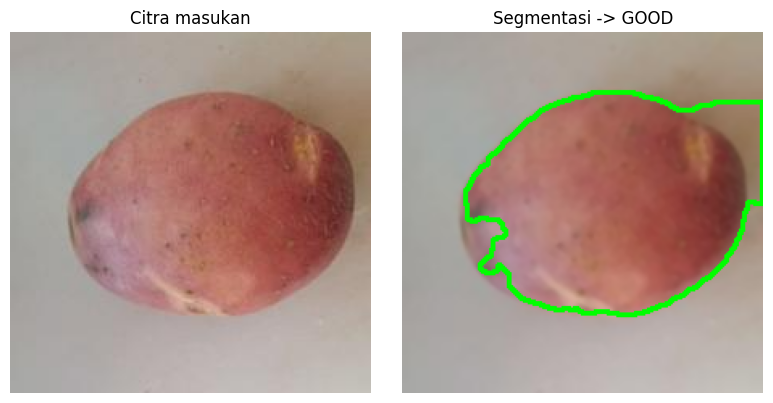

label asli: Bad: 3 dari 3 indikator melewati ambang (Bad bila >= 2)  ->  BAD
   rough_ratio   0.1143  (ambang 0.0501)  <- melewati
   dark_ratio    0.0608  (ambang 0.0260)  <- melewati
   bright_ratio  0.0238  (ambang 0.0061)  <- melewati


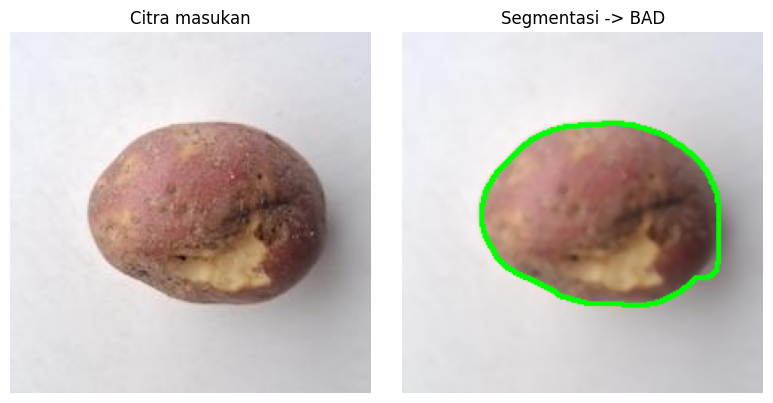

In [21]:
# Contoh: satu citra Good dan satu citra Bad dari test set
for k, lab in KELAS.items():
    d = os.path.join(DATA_DIR, "test", k)
    p = os.path.join(d, random.choice(os.listdir(d)))
    hasil = prediksi_dan_tampilkan(p, judul=f"label asli: {NAMA_LABEL[lab]}")

### Pilih foto sendiri dari laptop
Klik *Choose Files* pada sel di bawah. Foto tersimpan sementara di sesi Colab.

Klik 'Choose Files', lalu pilih foto kentang dari laptopmu (boleh lebih dari satu).


Saving gelap.jpeg to gelap.jpeg
gelap.jpeg: 0 dari 3 indikator melewati ambang (Bad bila >= 2)  ->  GOOD
   rough_ratio   0.0175  (ambang 0.0501)
   dark_ratio    0.0110  (ambang 0.0260)
   bright_ratio  0.0000  (ambang 0.0061)


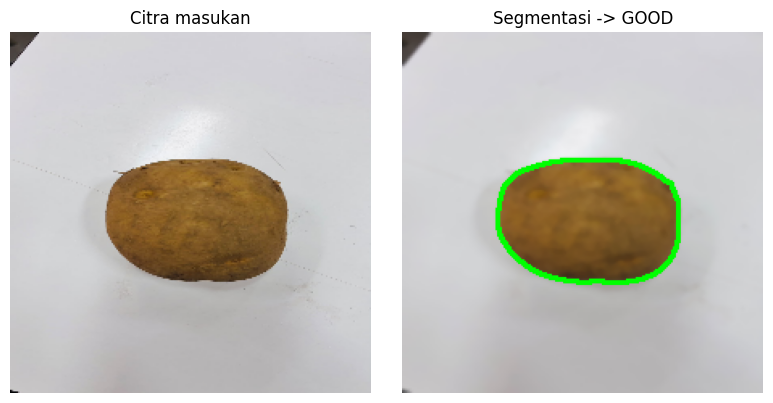

In [26]:
from google.colab import files

print("Klik 'Choose Files', lalu pilih foto kentang dari laptopmu (boleh lebih dari satu).")
unggahan = files.upload()
for path in unggahan.keys():
    prediksi_dan_tampilkan(path)

## Opsional: classifier sebagai pembanding
Bagian ini **tidak wajib**. Fungsinya hanya membandingkan aturan ambang dengan classifier (SVM, Random Forest, KNN) yang memakai seluruh fitur manual. Set `JALANKAN_PEMBANDING = False` untuk melewatinya.

In [23]:
if JALANKAN_PEMBANDING:
    from sklearn.ensemble import RandomForestClassifier
    from sklearn.svm import SVC
    from sklearn.neighbors import KNeighborsClassifier
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler

    KOLOM = [c for c in df_tr.columns if c not in ("label", "path")]
    Xtr, ytr, Xva, yva, Xte = df_tr[KOLOM], df_tr.label, df_va[KOLOM], df_va.label, df_te[KOLOM]
    MODEL = {
        "SVM (RBF)": make_pipeline(StandardScaler(), SVC(C=10, gamma="scale", random_state=SEED)),
        "Random Forest": RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED),
        "KNN (k=7)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7)),
    }
    baris = [{"Metode": f"Aturan ambang (N={MIN_VOTE})", "F1 val": f1_score(df_va.label, (jumlah_suara(df_va) >= MIN_VOTE).astype(int)),
              **{k: v for k, v in HASIL_ATURAN.items()}}]
    for nama, m in MODEL.items():
        m.fit(Xtr, ytr)
        p = m.predict(Xte)
        baris.append({"Metode": nama, "F1 val": f1_score(yva, m.predict(Xva)), "Acc test": accuracy_score(yte, p),
                      "Precision": precision_score(yte, p), "Recall": recall_score(yte, p), "F1 test": f1_score(yte, p)})
    df_banding = pd.DataFrame(baris).round(4)
    df_banding.to_csv(os.path.join(OUT_DIR, "perbandingan_metode.csv"), index=False)
    print(df_banding.to_string(index=False))
else:
    print("Bagian pembanding dilewati (JALANKAN_PEMBANDING = False).")

             Metode  F1 val  Acc test  Precision  Recall  F1 test
Aturan ambang (N=2)  0.7969     0.795     0.7547   0.874   0.8100
          SVM (RBF)  0.9917     0.993     0.9940   0.992   0.9930
      Random Forest  0.9866     0.981     0.9839   0.978   0.9809
          KNN (k=7)  0.9597     0.969     0.9796   0.958   0.9687


### Uji bias latar
Sel ini memeriksa apakah kelas bisa ditebak **hanya dari latar foto**. Bila akurasinya jauh di atas 50%, classifier yang memakai fitur warna dan tekstur ikut diuntungkan oleh perbedaan kondisi foto, bukan hanya oleh kondisi kentangnya.

In [24]:
if JALANKAN_PEMBANDING:
    from sklearn.model_selection import cross_val_score
    # Uji: seberapa baik kelas bisa ditebak HANYA dari piksel LATAR (tanpa kentang sama sekali)?
    rows = []
    for k, lab in KELAS.items():
        d = os.path.join(DATA_DIR, "train", k)
        for f in random.sample(os.listdir(d), min(300, len(os.listdir(d)))):
            lab8 = cv2.cvtColor(akuisisi(os.path.join(d, f)), cv2.COLOR_BGR2LAB).astype(np.float32)
            b = 10
            ring = np.concatenate([lab8[:b].reshape(-1, 3), lab8[-b:].reshape(-1, 3),
                                   lab8[:, :b].reshape(-1, 3), lab8[:, -b:].reshape(-1, 3)])
            c = np.median(ring, axis=0)
            rows.append({"label": lab, "bgL": c[0], "bgA": c[1], "bgB": c[2], "bgStd": ring[:, 0].std()})
    dfb = pd.DataFrame(rows)
    akurasi_bg = cross_val_score(RandomForestClassifier(200, random_state=SEED), dfb.drop(columns="label"), dfb.label, cv=5).mean()
    print(f"Akurasi menebak kelas hanya dari LATAR: {akurasi_bg:.1%}  (tebakan acak = 50%)")
    if akurasi_bg > 0.60:
        print("-> Foto kelas Good dan Bad diambil dengan kondisi latar/cahaya yang sedikit berbeda.")
        print("   Classifier bisa ikut memanfaatkannya, jadi akurasinya di alat nyata bisa lebih rendah.")
        print("   Aturan ambang memakai lebih sedikit fitur sehingga lebih mudah dijelaskan, tetapi belum tentu kebal bias.")
        print("   Pastikan diuji dengan foto dari webcam di alat yang sebenarnya.")

Akurasi menebak kelas hanya dari LATAR: 76.5%  (tebakan acak = 50%)
-> Foto kelas Good dan Bad diambil dengan kondisi latar/cahaya yang sedikit berbeda.
   Classifier bisa ikut memanfaatkannya, jadi akurasinya di alat nyata bisa lebih rendah.
   Aturan ambang memakai lebih sedikit fitur sehingga lebih mudah dijelaskan, tetapi belum tentu kebal bias.
   Pastikan diuji dengan foto dari webcam di alat yang sebenarnya.
